In [1]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# 1. Khai báo các thư viện vào bài làm
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import os
print("Đã khai báo các thư viện cần thiết thành công!")


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT
Đã khai báo các thư viện cần thiết thành công!


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT


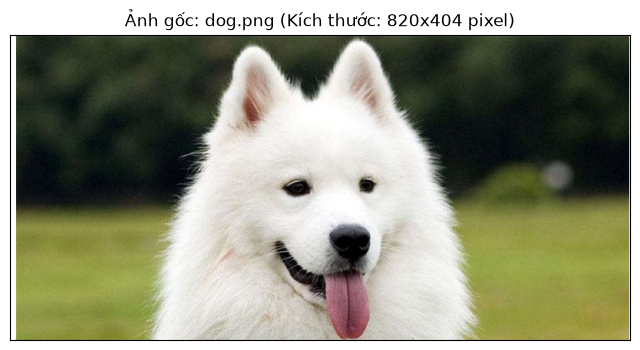

In [2]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# 2. Đọc vào file ảnh cần giảm kích thước và hiển thị ra màn hình
image_path = 'dog.png'
image = Image.open(image_path)

plt.figure(figsize=(8, 5))
axes = plt.axes(xticks=[], yticks=[])
axes.imshow(image)
plt.title(f"Ảnh gốc: dog.png (Kích thước: {image.size[0]}x{image.size[1]} pixel)")
plt.show()


In [4]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# 3. Chuyển ảnh đọc được thành mảng số và biến đổi về mảng 2 chiều chuẩn hóa [0, 1]
imarr = np.array(image)
rows = imarr.shape[0]
cols = imarr.shape[1]
print(f"Kích thước mảng ảnh 3 chiều (rows x cols x channels): {imarr.shape}")

# Biến đổi các giá trị màu từ đoạn [0...255] về đoạn [0...1] và chuyển dạng mảng từ 3 chiều thành 2 chiều
data = imarr / 255.0
data = data.reshape(rows * cols, 3)

print("Kích thước mảng dữ liệu 2 chiều (data.shape):", data.shape)
print(f"Số lượng điểm ảnh (pixels): {rows * cols:,}")


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT
Kích thước mảng ảnh 3 chiều (rows x cols x channels): (404, 820, 3)
Kích thước mảng dữ liệu 2 chiều (data.shape): (331280, 3)
Số lượng điểm ảnh (pixels): 331,280


In [5]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# 4. Chạy thuật toán gom cụm với số màu mong muốn là 32 và lấy mảng biểu diễn sau gom cụm
n_colors = 32
print(f"Đang chạy thuật toán K-Means để gom {data.shape[0]} điểm ảnh về {n_colors} màu đại diện...")
kmeans = KMeans(n_clusters=n_colors, max_iter=300, random_state=42)
kmeans.fit(data)

# Lấy ra mảng biểu diễn màu mới sau khi gom cụm
new_colors = kmeans.cluster_centers_[kmeans.predict(data)]
print("Đã hoàn thành gom cụm màu!")
print("Kích thước mảng màu mới:", new_colors.shape)


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT
Đang chạy thuật toán K-Means để gom 331280 điểm ảnh về 32 màu đại diện...
Đã hoàn thành gom cụm màu!
Kích thước mảng màu mới: (331280, 3)


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT


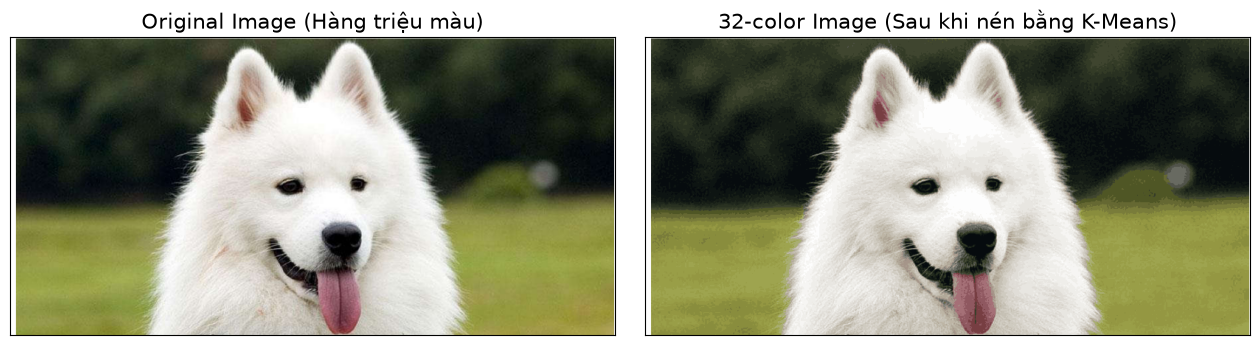

In [6]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# 5. Khôi phục dạng mảng từ 2 chiều thành 3 chiều và so sánh với ảnh gốc
img_recolored = new_colors.reshape(imarr.shape)

fig, ax = plt.subplots(1, 2, figsize=(16, 6), subplot_kw=dict(xticks=[], yticks=[]))
fig.subplots_adjust(wspace=0.05)
ax[0].imshow(image)
ax[0].set_title(f'Original Image (Hàng triệu màu)', size=15)
ax[1].imshow(img_recolored)
ax[1].set_title(f'{n_colors}-color Image (Sau khi nén bằng K-Means)', size=15)
plt.show()


In [7]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# 6. Lưu hình kết quả xuống đĩa cứng và so sánh dung lượng file
output_path = 'compressed_img2.png'
# Chuyển về thang đo 0-255 định dạng uint8
img_save = (img_recolored * 255).astype(np.uint8)
new_img = Image.fromarray(img_save)
new_img.save(output_path)

# So sánh dung lượng file
orig_size_bytes = os.path.getsize(image_path)
comp_size_bytes = os.path.getsize(output_path)

print("--- SO SÁNH DUNG LƯỢNG FILE ẢNH ---")
print(f"File ảnh gốc ({image_path}):          {orig_size_bytes / 1024:.2f} KB ({orig_size_bytes:,} bytes)")
print(f"File ảnh nén ({output_path}):      {comp_size_bytes / 1024:.2f} KB ({comp_size_bytes:,} bytes)")
print(f"Tỷ lệ giảm dung lượng:                  {(1 - comp_size_bytes / orig_size_bytes) * 100:.2f}%")

print("""
NHẬN XÉT:
1. Thuật toán K-Means gom cụm không gian màu RGB từ hàng triệu màu thực tế xuống chỉ còn 32 màu chủ đạo.
2. Mặc dù số lượng màu giảm mạnh, các chi tiết nhận diện của chú chó (bộ lông trắng, chiếc lưỡi hồng, đôi mắt đen và bãi cỏ xanh phía sau) vẫn được bảo toàn rất rõ ràng.
3. Kỹ thuật Lượng tử hóa màu (Color Quantization) bằng K-Means là một ứng dụng rất phổ biến trong nén ảnh và truyền tải đồ họa mạng.
""")


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT
--- SO SÁNH DUNG LƯỢNG FILE ẢNH ---
File ảnh gốc (dog.png):          316.94 KB (324,544 bytes)
File ảnh nén (compressed_img2.png):      114.72 KB (117,477 bytes)
Tỷ lệ giảm dung lượng:                  63.80%

NHẬN XÉT:
1. Thuật toán K-Means gom cụm không gian màu RGB từ hàng triệu màu thực tế xuống chỉ còn 32 màu chủ đạo.
2. Mặc dù số lượng màu giảm mạnh, các chi tiết nhận diện của chú chó (bộ lông trắng, chiếc lưỡi hồng, đôi mắt đen và bãi cỏ xanh phía sau) vẫn được bảo toàn rất rõ ràng.
3. Kỹ thuật Lượng tử hóa màu (Color Quantization) bằng K-Means là một ứng dụng rất phổ biến trong nén ảnh và truyền tải đồ họa mạng.

